# Phase 2: Remaining Useful Life Prediction with Sequence Models

**Dataset:** NASA C-MAPSS turbofan engine degradation, subset FD001
**Team T017:** Kush Puri, Aadit Vachher, Vachan Gupta, Aabir Sarkar, Kushagra Maheshwari
**Models:** LSTM on raw sensor windows (main), 1D temporal CNN, MLP on engineered features, and a hybrid LSTM + engineered-feature model

Phase 1 showed that a Random Forest on 57 hand-engineered features predicts RUL well. Phase 2 asks the project's central question: **can a sequence model learn the degradation signal directly from raw sensor windows, and does combining it with the engineered features help?**

Everything that is not the model is kept identical to Phase 1: same files, same RUL target (uncapped), same flat-sensor rule, same 5 `GroupKFold` folds on engine ID, same metrics, same single use of the test set.

## 1. What changes from Phase 1, and what does not

| | Phase 1 | Phase 2 |
|---|---|---|
| Input per prediction | one row of 57 engineered features | a window of the last `W` cycles of 14 raw (normalised) sensors |
| Model | Naive, Elastic Net, Random Forest | LSTM, temporal CNN, MLP, hybrid LSTM + features |
| Target | RUL = last cycle − current cycle, uncapped | same (divided by 100 for training only, multiplied back for scoring) |
| Sensors | 14 kept (std < 0.01 dropped) | same 14 |
| Split | 5-fold `GroupKFold` on engine ID | the **same** 5 folds |
| Metrics | RMSE, MAE, MAE early (RUL ≥ 50), MAE late (RUL < 50) | same |
| Test | last cycle of each test engine, scored once | same |

Keeping these fixed means any change in score comes from the model and its input, not from a different evaluation.

## 2. Deep learning literature review

<!-- TODO (team): read each paper and confirm the details below against the original before submission. Entries marked [verify] are the least certain. -->

- **Hochreiter and Schmidhuber (1997), "Long Short-Term Memory", *Neural Computation*.** Plain recurrent networks struggle to learn long-range dependencies because gradients shrink or blow up as they are passed back through many time steps. The LSTM adds a cell state controlled by gates (input, forget, output; the forget gate was added later by Gers et al., 2000) so information and gradients can flow across many steps. This is the basis of our main model.
- **Saxena, Goebel, Simon and Eklund (2008), "Damage propagation modeling for aircraft engine run-to-failure simulation", PHM conference.** Describes how C-MAPSS was used to generate the run-to-failure trajectories, and the scoring used in the 2008 PHM challenge. It explains why every training engine ends in failure and why test engines are cut off early.
- **Heimes (2008), "Recurrent neural networks for remaining useful life estimation", PHM conference.** [verify] One of the first recurrent-network approaches on the C-MAPSS challenge data. It is also commonly credited with the piecewise-linear target (capping RUL at a constant early in life), which we test as a secondary comparison in Phase 1.
- **Babu, Zhao and Li (2016), "Deep convolutional neural network based regression approach for estimation of remaining useful life", DASFAA.** [verify] Applies 1D convolutions over time windows of C-MAPSS sensors. Motivates our temporal CNN comparison.
- **Zheng, Ristovski, Farahat and Gupta (2017), "Long short-term memory network for remaining useful life estimation", IEEE ICPHM.** [verify] Applies stacked LSTM layers to C-MAPSS windows and reports gains over CNN and classical baselines. Closest to our main model.
- **Srivastava et al. (2014), "Dropout: a simple way to prevent neural networks from overfitting", *JMLR*.** Randomly zeroes units during training so the network cannot rely on any single unit. Used here between LSTM layers and in the head, and tested in an ablation.

**Important difference from most papers.** Most C-MAPSS papers cap RUL at around 125 and score only on the test set. We keep RUL uncapped (the brief does not ask for a cap) and score with engine-level CV, so our numbers are **not directly comparable** to published ones.

## 3. Setup

The notebook looks for the three data files in `../data/` (repo layout), `data/`, or the current folder (Colab upload). A fixed seed is set for NumPy and PyTorch. Training runs on CPU unless a CUDA GPU is available; on CPU the full notebook takes roughly 20 to 40 minutes.

In [1]:
import os, random, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import GroupKFold

RANDOM_STATE = 42
EARLY_LATE_THRESHOLD = 50   # same as Phase 1
WINDOW_FEAT = 5             # Phase 1 rolling window (for the engineered features)
BASE_N = 10                 # Phase 1 healthy-baseline length
RUL_SCALE = 100.0           # target is divided by this for training only

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(max(1, os.cpu_count() or 1))


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(RANDOM_STATE)

FIG_DIR = Path("../reports/figures")
QUICK = os.environ.get("RUL_QUICK") == "1"   # smoke-test mode: 2 epochs per model


def save_fig(name):
    if FIG_DIR.exists():
        plt.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")

DATA_DIR = next(p for p in [Path("../data"), Path("data"), Path(".")] if (p / "train_FD001.txt").exists())

sensor_cols = [f"s{i}" for i in range(1, 22)]
op_cols = ["op1", "op2", "op3"]
cols = ["engine_id", "cycle"] + op_cols + sensor_cols

train = pd.read_csv(DATA_DIR / "train_FD001.txt", sep=r"\s+", header=None, names=cols)
test = pd.read_csv(DATA_DIR / "test_FD001.txt", sep=r"\s+", header=None, names=cols)
rul_test = pd.read_csv(DATA_DIR / "RUL_FD001.txt", sep=r"\s+", header=None, names=["RUL"])

# Same row order as Phase 1, so GroupKFold gives the same folds
train = train.sort_values(["engine_id", "cycle"]).reset_index(drop=True)
test = test.sort_values(["engine_id", "cycle"]).reset_index(drop=True)

print("PyTorch", torch.__version__, "| device:", DEVICE, "| data from:", DATA_DIR.resolve())
print("Train:", train.shape, "| Test:", test.shape, "| RUL file:", rul_test.shape)

PyTorch 2.15.0 | device: cpu | data from: /Users/aabirsarkar/Desktop/DL project/data
Train: (20631, 26) | Test: (13096, 26) | RUL file: (100, 1)


## 4. Target and sensors (identical to Phase 1)

RUL = last cycle of the engine − current cycle, uncapped. Sensors with training standard deviation below 0.01 are dropped, leaving the same 14 as in Phase 1.

In [2]:
train["RUL"] = train.groupby("engine_id")["cycle"].transform("max") - train["cycle"]

train_std = train[sensor_cols].std()
drop_sensors = train_std[train_std < 0.01].index.tolist()
keep_sensors = [s for s in sensor_cols if s not in drop_sensors]
print("Dropped:", drop_sensors)
print("Kept (%d):" % len(keep_sensors), keep_sensors)

Dropped: ['s1', 's5', 's6', 's10', 's16', 's18', 's19']
Kept (14): ['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']


## 5. Phase 1 features (for the hybrid and the MLP)

The same `build_features` function as Phase 1, copied unchanged: cycle, 14 raw sensors, and per sensor a rolling mean, two-point rolling slope (window 5) and health (drift from the engine's own first 10 cycles, set to 0 before cycle 10). All causal, all per engine.

In [3]:
def build_features(df, w=WINDOW_FEAT, base_n=BASE_N):
    df = df.sort_values(["engine_id", "cycle"]).copy()
    g = df.groupby("engine_id")
    new_cols = []
    for s in keep_sensors:
        df[f"{s}_mean"] = g[s].transform(lambda x: x.rolling(w, min_periods=1).mean())
        df[f"{s}_slope"] = g[s].transform(lambda x: (x - x.shift(w - 1)) / (w - 1)).fillna(0)
        baseline = g[s].transform(lambda x: x.iloc[:base_n].mean())
        df[f"{s}_health"] = (df[s] - baseline).where(df["cycle"] >= base_n, 0.0)
        new_cols += [f"{s}_mean", f"{s}_slope", f"{s}_health"]
    return df, ["cycle"] + keep_sensors + new_cols


train_f, feature_cols = build_features(train)
test_f, _ = build_features(test)
assert (train_f.index == train.index).all()
print("Engineered features:", len(feature_cols))

Engineered features: 57


## 6. Sequence windows

For every row (engine `e`, cycle `t`) the model sees the window of cycles `t − W + 1 … t` of the same engine, i.e. the current reading and the `W − 1` before it.

- **Engine boundaries.** Windows are built per engine, so no window ever contains readings from two engines.
- **Early cycles.** For `t < W` there is not enough history. We pad by repeating that engine's **first** reading at the front. This uses only the past, and it means every row gets a prediction, exactly as in Phase 1. So CV is scored on the same 20,631 rows.
- **Causality.** A window ending at `t` contains nothing after `t`.

Raw windows hold unscaled sensor values. Normalisation is applied per fold (Section 8), using the training engines only.

In [4]:
def make_windows(df, W):
    # Returns array (n_rows, W, n_sensors) aligned with df's row order (sorted by engine, cycle).
    out = []
    for _, d in df.groupby("engine_id", sort=True):
        x = d[keep_sensors].values.astype(np.float32)
        pad = np.repeat(x[:1], W - 1, axis=0)
        xp = np.concatenate([pad, x], axis=0)
        win = np.lib.stride_tricks.sliding_window_view(xp, W, axis=0)  # (n, n_sensors, W)
        out.append(win.transpose(0, 2, 1))
    return np.ascontiguousarray(np.concatenate(out, axis=0))


Xw = make_windows(train, 30)
print("Window array for W=30:", Xw.shape)

# Sanity checks: window ending at row i ends with row i, and engine 1 cycle 1 is all padding
assert np.allclose(Xw[:, -1, :], train[keep_sensors].values)
assert np.allclose(Xw[0], train.loc[0, keep_sensors].values)
e2_start = train.index[train["engine_id"] == 2][0]
assert np.allclose(Xw[e2_start], train.loc[e2_start, keep_sensors].values)  # no leak from engine 1
print("Window checks passed: aligned with rows, no cross-engine windows.")

Window array for W=30: (20631, 30, 14)
Window checks passed: aligned with rows, no cross-engine windows.


## 7. Models

All models output one number (scaled RUL) and share the same small regression head: `Linear(→32) → ReLU → Dropout → Linear(32→1)`.

- **LSTM (main model).** Two stacked LSTM layers, hidden size 64, dropout 0.2 between layers. The hidden state at the last time step summarises the window and feeds the head. *Why LSTM:* the brief suggests it, it is designed for sequences where the order matters, and its gates let it keep information across the whole window (Hochreiter and Schmidhuber, 1997).
- **Temporal CNN (comparison).** Two 1D convolution layers (kernel 5, 32 then 64 channels) over time, then global average pooling. *Why:* a CNN looks at local patterns in time and is a common, faster alternative (Babu et al., 2016). Comparing it with the LSTM tests whether the recurrent structure matters.
- **MLP on engineered features (control).** The same head, fed only the 57 Phase 1 features at the current row. *Why:* it isolates what the features contribute in a neural model, so the hybrid's gain can be attributed.
- **Hybrid LSTM + features.** The LSTM's last hidden state (64 values) is concatenated with the 57 engineered features (standardised), then passed to the head. *Why:* a 30-cycle window cannot see an engine's healthy start or how long it has been running. The Phase 1 Random Forest relied heavily on exactly those signals (`cycle` had importance 0.56, and the health features compare with cycles 1 to 10). The hybrid gives the network both the short-term sequence and the long-term context, each from the component best placed to supply it.

**Size check.** The networks are small (tens of thousands of parameters) because there are only about 16,500 training rows per fold and these rows are highly correlated within each engine.

In [5]:
class Head(nn.Module):
    def __init__(self, d_in, dropout):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_in, 32), nn.ReLU(), nn.Dropout(dropout), nn.Linear(32, 1))

    def forward(self, z):
        return self.net(z).squeeze(-1)


class LSTMRegressor(nn.Module):
    def __init__(self, n_in, hidden=64, layers=2, dropout=0.2, n_static=0):
        super().__init__()
        self.lstm = nn.LSTM(n_in, hidden, num_layers=layers, batch_first=True,
                            dropout=dropout if layers > 1 else 0.0)
        self.head = Head(hidden + n_static, dropout)

    def forward(self, x, s=None):
        out, _ = self.lstm(x)
        z = out[:, -1, :]                       # hidden state at the last (current) cycle
        if s is not None:
            z = torch.cat([z, s], dim=1)        # hybrid: add engineered features
        return self.head(z)


class CNNRegressor(nn.Module):
    def __init__(self, n_in, dropout=0.2):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv1d(n_in, 32, kernel_size=5, padding=2), nn.ReLU(),
            nn.Conv1d(32, 64, kernel_size=5, padding=2), nn.ReLU(),
        )
        self.head = Head(64, dropout)

    def forward(self, x, s=None):
        z = self.conv(x.transpose(1, 2)).mean(dim=2)   # (batch, channels, time) -> average over time
        return self.head(z)


class MLPRegressor(nn.Module):
    def __init__(self, n_static, dropout=0.2):
        super().__init__()
        self.body = nn.Sequential(nn.Linear(n_static, 64), nn.ReLU(), nn.Dropout(dropout))
        self.head = Head(64, dropout)

    def forward(self, x, s):
        return self.head(self.body(s))


def n_params(m):
    return sum(p.numel() for p in m.parameters())


n_s, n_f = len(keep_sensors), len(feature_cols)
for name, m in [("LSTM", LSTMRegressor(n_s)), ("CNN", CNNRegressor(n_s)),
                ("MLP", MLPRegressor(n_f)), ("Hybrid", LSTMRegressor(n_s, n_static=n_f))]:
    print(f"{name:7s} parameters: {n_params(m):,}")

LSTM    parameters: 55,873
CNN     parameters: 14,689
MLP     parameters: 5,825
Hybrid  parameters: 57,697


## 8. Training and evaluation protocol

**Outer loop (model assessment).** The same 5-fold `GroupKFold` on engine ID as Phase 1. Each fold trains on 80 engines and predicts all rows of the other 20. Metrics are reported as mean ± std across folds.

**Inside each training fold:**
1. **Normalisation.** Per-sensor mean and std are computed on the fold's training engines only, then applied to its training, validation and held-out windows. FD001 has one operating regime, so this is the same as the brief's "normalise by training operating regime". Engineered features (hybrid, MLP) are standardised the same way.
2. **Early-stopping split.** Every 5th training engine (sorted by ID) is held back as an inner validation set (16 engines). The model trains on the other 64. This keeps the outer held-out engines completely unseen.
3. **Training.** Adam, learning rate 1e-3, weight decay 1e-4 (L2 regularisation), batch 256, MSE loss on RUL/100, gradient-norm clipping at 1.0, up to 40 epochs. Training stops when inner validation loss has not improved for 6 epochs, and the best-epoch weights are restored.
4. **Prediction.** Predictions on the held-out fold are multiplied by 100 to get cycles, and clipped at 0 because RUL cannot be negative.

**Why these choices.**
- *RUL / 100:* targets range 0 to 361. Dividing keeps the output near the scale of the inputs so training is stable. It is a pure rescale, not a cap; scoring uses the original cycles.
- *Early stopping and weight decay:* the main regularisers. Rows within an engine are nearly duplicates, so a network can memorise training engines fast.
- *Gradient clipping:* standard for LSTMs, prevents occasional exploding gradients.
- *Hyperparameters* are fixed, reasonable defaults, not tuned (same policy as Phase 1). The ablations in Section 11 vary the most important ones.

**Final models.** Each model is retrained on all 100 training engines for the median best epoch found in CV, with 3 seeds. The test set is scored once at each engine's last cycle; we report the mean ± std over seeds and the score of the 3-seed average prediction.

In [6]:
gkf = GroupKFold(n_splits=5)
y_all = train["RUL"].values.astype(np.float32)
groups = train["engine_id"].values
FOLDS = list(gkf.split(np.zeros(len(train)), y_all, groups))


def metrics(y_true, y_pred):
    err = np.abs(y_true - y_pred)
    late = y_true < EARLY_LATE_THRESHOLD
    return {
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "MAE early": float(err[~late].mean()),
        "MAE late": float(err[late].mean()),
    }


def summarize(fold_df):
    return pd.Series({c: f"{fold_df[c].mean():.2f} ± {fold_df[c].std():.2f}" for c in fold_df.columns})


CFG = dict(arch="lstm", W=30, dropout=0.2, hybrid=False, lr=1e-3, wd=1e-4,
           batch=256, max_epochs=2 if QUICK else 40, patience=6, cap=None)


def build_model(cfg):
    if cfg["arch"] == "lstm":
        return LSTMRegressor(n_s, dropout=cfg["dropout"], n_static=n_f if cfg["hybrid"] else 0)
    if cfg["arch"] == "cnn":
        return CNNRegressor(n_s, dropout=cfg["dropout"])
    if cfg["arch"] == "mlp":
        return MLPRegressor(n_f, dropout=cfg["dropout"])
    raise ValueError(cfg["arch"])


def uses_static(cfg):
    return cfg["hybrid"] or cfg["arch"] == "mlp"


def to_t(a):
    return torch.as_tensor(a, dtype=torch.float32, device=DEVICE)


def predict(model, Xw_, S_, batch=2048):
    model.eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(Xw_), batch):
            s = to_t(S_[i:i + batch]) if S_ is not None else None
            out.append(model(to_t(Xw_[i:i + batch]), s).cpu().numpy())
    return np.concatenate(out) * RUL_SCALE


def fit(cfg, Xtr, Str, ytr, Xva=None, Sva=None, yva=None, epochs=None, seed=RANDOM_STATE):
    # Trains one model. With a validation set: early stopping. Without: fixed number of epochs.
    set_seed(seed)
    model = build_model(cfg).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"], weight_decay=cfg["wd"])
    loss_fn = nn.MSELoss()
    yt = ytr if cfg["cap"] is None else np.minimum(ytr, cfg["cap"])
    yt = yt / RUL_SCALE
    n = len(Xtr)
    g = torch.Generator().manual_seed(seed)
    max_ep = epochs if epochs is not None else cfg["max_epochs"]
    best, best_ep, best_state, wait, hist = np.inf, 0, None, 0, []
    for ep in range(1, max_ep + 1):
        model.train()
        perm = torch.randperm(n, generator=g).numpy()
        tr_loss = 0.0
        for i in range(0, n, cfg["batch"]):
            idx = perm[i:i + cfg["batch"]]
            s = to_t(Str[idx]) if Str is not None else None
            opt.zero_grad()
            loss = loss_fn(model(to_t(Xtr[idx]), s), to_t(yt[idx]))
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            tr_loss += loss.item() * len(idx)
        rec = {"epoch": ep, "train_rmse": np.sqrt(tr_loss / n) * RUL_SCALE}
        if Xva is not None:
            yv = yva if cfg["cap"] is None else np.minimum(yva, cfg["cap"])
            va_rmse = float(np.sqrt(np.mean((predict(model, Xva, Sva) - yv) ** 2)))
            rec["val_rmse"] = va_rmse
            if va_rmse < best - 1e-4:
                best, best_ep, wait = va_rmse, ep, 0
                best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            else:
                wait += 1
                if wait >= cfg["patience"]:
                    hist.append(rec)
                    break
        hist.append(rec)
    if best_state is not None:
        model.load_state_dict(best_state)
    else:
        best_ep = max_ep
    return model, best_ep, pd.DataFrame(hist)


def standardise(train_part, *others, axis=0):
    mu = train_part.mean(axis=axis, keepdims=True)
    sd = train_part.std(axis=axis, keepdims=True) + 1e-8
    return [(a - mu) / sd for a in (train_part,) + others]

In [7]:
WIN_CACHE = {}
F_all = train_f[feature_cols].values.astype(np.float32)


def get_windows(W):
    if W not in WIN_CACHE:
        WIN_CACHE[W] = make_windows(train, W)
    return WIN_CACHE[W]


def run_cv(cfg, name, verbose=True):
    # 5-fold GroupKFold CV with early stopping. Returns out-of-fold predictions, fold metrics, best epochs, histories.
    Xw_ = get_windows(cfg["W"])
    oof = np.zeros(len(train), dtype=np.float32)
    rows, best_eps, hists = [], [], []
    t0 = time.time()
    for k, (tr_idx, te_idx) in enumerate(FOLDS):
        tr_eng = np.sort(np.unique(groups[tr_idx]))
        va_eng = tr_eng[::5]                                   # every 5th training engine
        is_va = np.isin(groups[tr_idx], va_eng)
        fit_idx, va_idx = tr_idx[~is_va], tr_idx[is_va]

        # Normalise sensors with statistics from the fitting engines only
        flat = Xw_[fit_idx][:, -1, :]                          # one reading per row, no padding duplicates
        mu, sd = flat.mean(0), flat.std(0) + 1e-8
        Xn = (Xw_ - mu) / sd
        S = None
        if uses_static(cfg):
            fmu, fsd = F_all[fit_idx].mean(0), F_all[fit_idx].std(0) + 1e-8
            S = (F_all - fmu) / fsd
        sub = (lambda idx: S[idx]) if S is not None else (lambda idx: None)

        model, best_ep, hist = fit(cfg, Xn[fit_idx], sub(fit_idx), y_all[fit_idx],
                                   Xn[va_idx], sub(va_idx), y_all[va_idx])
        oof[te_idx] = np.clip(predict(model, Xn[te_idx], sub(te_idx)), 0, None)
        rows.append(metrics(y_all[te_idx], oof[te_idx]))
        best_eps.append(best_ep)
        hists.append(hist)
    folds = pd.DataFrame(rows)
    if verbose:
        print(f"{name:32s} RMSE {folds['RMSE'].mean():6.2f} ± {folds['RMSE'].std():4.2f} | "
              f"MAE {folds['MAE'].mean():6.2f} | best epochs {best_eps} | {time.time() - t0:5.0f}s")
    return dict(oof=oof, folds=folds, best_eps=best_eps, hists=hists, cfg=cfg)

## 9. Phase 1 reference: Random Forest, re-run on the same folds

To compare like with like, the Phase 1 Random Forest (200 trees, `min_samples_leaf=5`, 57 features) is re-run here on the exact folds used for the deep models. Its scores should match Phase 1 (CV RMSE 34.78, MAE 22.79) up to small library-version differences.

In [8]:
rf_oof = np.zeros(len(train))
rf_rows = []
for tr_idx, te_idx in FOLDS:
    rf = RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=RANDOM_STATE, n_jobs=-1)
    rf.fit(F_all[tr_idx], y_all[tr_idx])
    rf_oof[te_idx] = rf.predict(F_all[te_idx])
    rf_rows.append(metrics(y_all[te_idx], rf_oof[te_idx]))
rf_folds = pd.DataFrame(rf_rows)
print("Random Forest (Phase 1 recipe), 5-fold CV:")
print(summarize(rf_folds).to_string())

Random Forest (Phase 1 recipe), 5-fold CV:
RMSE         35.17 ± 1.52
MAE          23.03 ± 1.23
MAE early    28.80 ± 1.47
MAE late      5.02 ± 0.52


## 10. Main model: LSTM on raw sensor windows (W = 30)

Window length 30 is the starting choice: it is shorter than the shortest test history (31 cycles), so every test engine has a full real window at its last cycle, and it is a common choice in C-MAPSS papers. Section 11 checks 10 and 50.

In [9]:
RESULTS = {}
RESULTS["LSTM (W=30)"] = run_cv(dict(CFG), "LSTM (W=30)")

LSTM (W=30)                      RMSE  41.76 ± 1.70 | MAE  29.81 | best epochs [3, 6, 3, 1, 1] |    86s


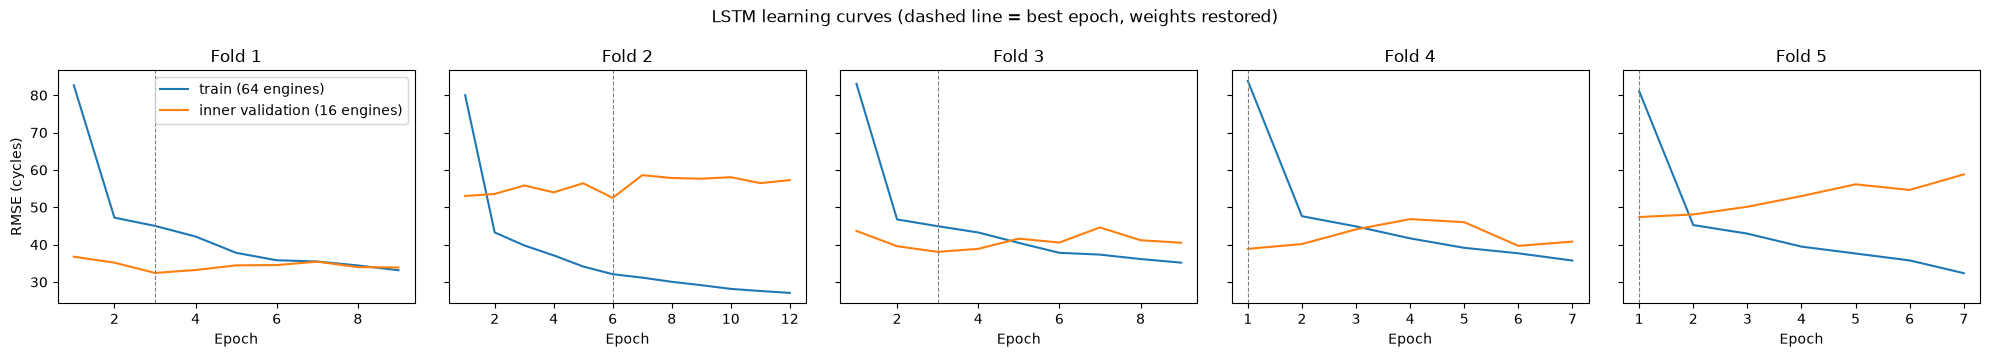

In [10]:
# Learning curves for each fold of the main LSTM (scaled back to cycles)
fig, axes = plt.subplots(1, 5, figsize=(20, 3.6), sharey=True)
for k, (ax, h) in enumerate(zip(axes, RESULTS["LSTM (W=30)"]["hists"])):
    ax.plot(h["epoch"], h["train_rmse"], label="train (64 engines)")
    ax.plot(h["epoch"], h["val_rmse"], label="inner validation (16 engines)")
    ax.axvline(RESULTS["LSTM (W=30)"]["best_eps"][k], color="grey", ls="--", lw=0.8)
    ax.set_title(f"Fold {k + 1}")
    ax.set_xlabel("Epoch")
axes[0].set_ylabel("RMSE (cycles)")
axes[0].legend()
plt.suptitle("LSTM learning curves (dashed line = best epoch, weights restored)")
plt.tight_layout()
save_fig("phase2_learning_curves.png")
plt.show()

## 11. Ablation studies

Each ablation changes **one** thing relative to the main LSTM (W = 30, dropout 0.2, raw windows, uncapped) and is scored on the same 5 folds.

| Ablation | Question it answers |
|---|---|
| Window 10 / 30 / 50 | How much history does the model need? |
| Dropout 0.0 vs 0.2 | Does dropout regularisation help, given early stopping and weight decay are already used? |
| LSTM vs temporal CNN | Does the recurrent structure matter, or do local temporal filters do as well? |
| Raw LSTM vs MLP on features vs hybrid | Where does the accuracy come from: the learned sequence, the engineered features, or both together? |
| Uncapped vs capped at 125 (hybrid) | Does the common piecewise-linear target help when scored on true RUL? |

In [11]:
ablations = {
    "LSTM (W=10)":                  dict(CFG, W=10),
    "LSTM (W=50)":                  dict(CFG, W=50),
    "LSTM (W=30, no dropout)":      dict(CFG, dropout=0.0),
    "Temporal CNN (W=30)":          dict(CFG, arch="cnn"),
    "MLP on 57 features":           dict(CFG, arch="mlp"),
    "Hybrid LSTM + features (W=30)": dict(CFG, hybrid=True),
    "Hybrid, capped at 125":        dict(CFG, hybrid=True, cap=125),
}
for name, cfg in ablations.items():
    RESULTS[name] = run_cv(cfg, name)

LSTM (W=10)                      RMSE  43.12 ± 0.99 | MAE  31.10 | best epochs [4, 2, 4, 2, 1] |    29s


LSTM (W=50)                      RMSE  41.61 ± 3.02 | MAE  29.66 | best epochs [3, 1, 13, 1, 1] |   150s


LSTM (W=30, no dropout)          RMSE  40.89 ± 3.59 | MAE  29.86 | best epochs [3, 1, 10, 1, 3] |    92s


Temporal CNN (W=30)              RMSE  44.06 ± 3.56 | MAE  31.69 | best epochs [7, 1, 6, 1, 8] |   110s


MLP on 57 features               RMSE  34.20 ± 3.27 | MAE  22.03 | best epochs [11, 11, 9, 11, 12] |     3s


Hybrid LSTM + features (W=30)    RMSE  35.05 ± 2.19 | MAE  23.76 | best epochs [11, 4, 10, 4, 5] |   122s


Hybrid, capped at 125            RMSE  46.02 ± 1.81 | MAE  27.72 | best epochs [40, 30, 33, 28, 37] |   351s


5-fold GroupKFold CV on 100 training engines, scored on uncapped RUL (mean ± std across folds)
                                       RMSE           MAE     MAE early      MAE late
Random Forest (Phase 1)        35.17 ± 1.52  23.03 ± 1.23  28.80 ± 1.47   5.02 ± 0.52
LSTM (W=30)                    41.76 ± 1.70  29.81 ± 2.00  35.40 ± 1.76  12.33 ± 3.97
LSTM (W=10)                    43.12 ± 0.99  31.10 ± 1.74  36.70 ± 1.49  13.60 ± 3.48
LSTM (W=50)                    41.61 ± 3.02  29.66 ± 3.57  35.26 ± 3.37  12.18 ± 4.91
LSTM (W=30, no dropout)        40.89 ± 3.59  29.86 ± 2.97  35.20 ± 3.22  13.14 ± 3.30
Temporal CNN (W=30)            44.06 ± 3.56  31.69 ± 2.40  36.97 ± 2.86  15.19 ± 3.30
MLP on 57 features             34.20 ± 3.27  22.03 ± 1.40  27.41 ± 1.74   5.23 ± 0.60
Hybrid LSTM + features (W=30)  35.05 ± 2.19  23.76 ± 1.16  29.45 ± 1.39   6.00 ± 0.58
Hybrid, capped at 125          46.02 ± 1.81  27.72 ± 0.44  35.44 ± 0.57   3.60 ± 0.20


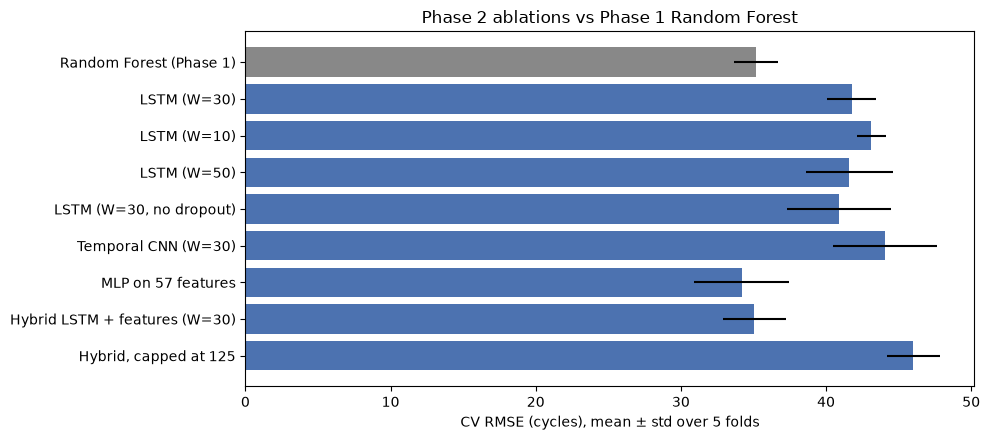

In [12]:
cv_table = pd.DataFrame({"Random Forest (Phase 1)": summarize(rf_folds),
                         **{n: summarize(r["folds"]) for n, r in RESULTS.items()}}).T
print("5-fold GroupKFold CV on 100 training engines, scored on uncapped RUL (mean ± std across folds)")
print(cv_table.to_string())

order = ["Random Forest (Phase 1)"] + list(RESULTS)
means = pd.DataFrame({"Random Forest (Phase 1)": rf_folds.mean(),
                      **{n: r["folds"].mean() for n, r in RESULTS.items()}}).T.loc[order]
stds = pd.DataFrame({"Random Forest (Phase 1)": rf_folds.std(),
                     **{n: r["folds"].std() for n, r in RESULTS.items()}}).T.loc[order]

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(range(len(order)), means["RMSE"], xerr=stds["RMSE"], color=["#888"] + ["#4C72B0"] * (len(order) - 1))
ax.set_yticks(range(len(order)))
ax.set_yticklabels(order)
ax.invert_yaxis()
ax.set_xlabel("CV RMSE (cycles), mean ± std over 5 folds")
ax.set_title("Phase 2 ablations vs Phase 1 Random Forest")
plt.tight_layout()
save_fig("phase2_ablation_rmse.png")
plt.show()

## 12. Error by RUL range (out of fold)

Mean absolute error for each 25-cycle range of true RUL, for the Phase 1 Random Forest, the raw LSTM and the hybrid. This shows *where* in an engine's life each model is accurate.

         Random Forest (Phase 1)  LSTM (W=30)  Hybrid LSTM + features  rows
0-25                         3.0     6.800000                4.000000  2500
25-50                        7.4    18.500000                8.300000  2500
50-75                       14.9    30.900000               17.200001  2500
75-100                      22.2    33.000000               26.200001  2500
100-125                     25.5    28.000000               28.000000  2500
125-150                     25.9    21.000000               24.200001  2424
150-175                     23.3    22.700001               20.500000  2070
175-200                     27.1    36.500000               26.000000  1579
200-225                     45.3    53.400002               42.900002   841
225-250                     68.6    80.900002               68.300003   491
250-275                     87.4   110.500000               91.699997   334
275-300                    116.2   137.699997              114.400002   144
300-325     

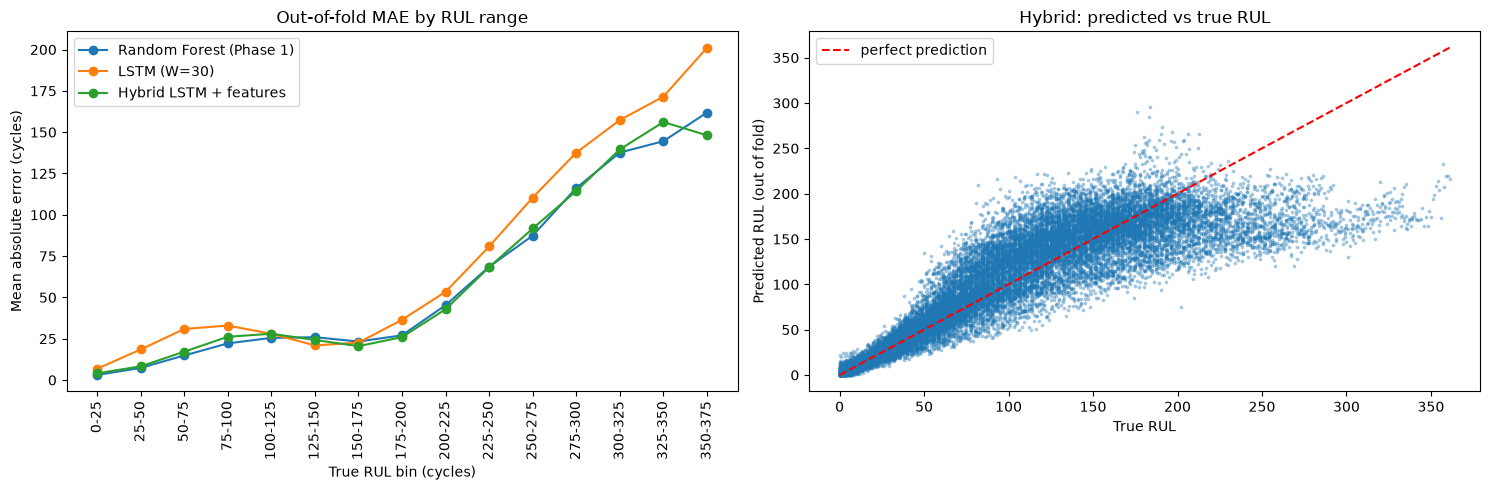

In [13]:
bins = pd.cut(pd.Series(y_all), bins=range(0, int(y_all.max()) + 25, 25))
curves = {
    "Random Forest (Phase 1)": rf_oof,
    "LSTM (W=30)": RESULTS["LSTM (W=30)"]["oof"],
    "Hybrid LSTM + features": RESULTS["Hybrid LSTM + features (W=30)"]["oof"],
}
err_tab = pd.DataFrame({n: pd.Series(np.abs(y_all - p)).groupby(bins, observed=True).mean()
                        for n, p in curves.items()})
err_tab["rows"] = pd.Series(1, index=range(len(y_all))).groupby(bins, observed=True).sum()
err_tab.index = [f"{int(b.left)}-{int(b.right)}" for b in err_tab.index]
print(err_tab.round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for n in curves:
    axes[0].plot(range(len(err_tab)), err_tab[n], marker="o", label=n)
axes[0].set_xticks(range(len(err_tab)))
axes[0].set_xticklabels(err_tab.index, rotation=90)
axes[0].set_xlabel("True RUL bin (cycles)")
axes[0].set_ylabel("Mean absolute error (cycles)")
axes[0].set_title("Out-of-fold MAE by RUL range")
axes[0].legend()

p = RESULTS["Hybrid LSTM + features (W=30)"]["oof"]
axes[1].scatter(y_all, p, s=3, alpha=0.3)
axes[1].plot([0, y_all.max()], [0, y_all.max()], "r--", label="perfect prediction")
axes[1].set_xlabel("True RUL")
axes[1].set_ylabel("Predicted RUL (out of fold)")
axes[1].set_title("Hybrid: predicted vs true RUL")
axes[1].legend()
plt.tight_layout()
save_fig("phase2_error_analysis.png")
plt.show()

## 13. Final models and test set

The test set is used **once**. Each model below is retrained on all 100 training engines (normalisation fitted on all training rows), for the median best epoch from its CV runs, with 3 seeds (42, 43, 44). Each test engine is scored at its last cycle against `RUL_FD001.txt`.

The Random Forest is retrained the same way as in Phase 1 for a side-by-side row.

In [14]:
SEEDS = [42, 43, 44]
FINAL = ["LSTM (W=30)", "Temporal CNN (W=30)", "MLP on 57 features", "Hybrid LSTM + features (W=30)"]

y_test = rul_test["RUL"].values.astype(np.float32)
test_last_idx = test.groupby("engine_id").tail(1).index.values           # rows are sorted by engine, cycle
F_test = test_f[feature_cols].values.astype(np.float32)[test_last_idx]
assert (test.loc[test_last_idx, "engine_id"].values == np.arange(1, 101)).all()

test_rows, test_preds = {}, {}

rf_final = RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=RANDOM_STATE, n_jobs=-1)
rf_final.fit(F_all, y_all)
test_preds["Random Forest (Phase 1)"] = rf_final.predict(F_test)
test_rows["Random Forest (Phase 1)"] = {k: f"{v:.2f}" for k, v in metrics(y_test, test_preds["Random Forest (Phase 1)"]).items()}

for name in FINAL:
    cfg = RESULTS[name]["cfg"]
    n_ep = int(np.median(RESULTS[name]["best_eps"]))
    Xtr_raw = get_windows(cfg["W"])
    Xte_raw = make_windows(test, cfg["W"])[test_last_idx]
    flat = Xtr_raw[:, -1, :]
    mu, sd = flat.mean(0), flat.std(0) + 1e-8
    Xtr, Xte = (Xtr_raw - mu) / sd, (Xte_raw - mu) / sd
    Str = Ste = None
    if uses_static(cfg):
        fmu, fsd = F_all.mean(0), F_all.std(0) + 1e-8
        Str, Ste = (F_all - fmu) / fsd, (F_test - fmu) / fsd
    per_seed, preds = [], []
    for seed in SEEDS:
        model, _, _ = fit(cfg, Xtr, Str, y_all, epochs=n_ep, seed=seed)
        p = np.clip(predict(model, Xte, Ste), 0, None)
        preds.append(p)
        per_seed.append(metrics(y_test, p))
    per_seed = pd.DataFrame(per_seed)
    ens = np.mean(preds, axis=0)
    test_preds[name] = ens
    row = {c: f"{per_seed[c].mean():.2f} ± {per_seed[c].std():.2f}" for c in per_seed.columns}
    row.update({f"{c} (3-seed avg)": f"{v:.2f}" for c, v in metrics(y_test, ens).items() if c in ("RMSE", "MAE")})
    row["epochs"] = n_ep
    test_rows[name] = row
    print(f"{name:32s} trained {n_ep} epochs x {len(SEEDS)} seeds | test RMSE {row['RMSE']}")

test_table = pd.DataFrame(test_rows).T.fillna("")
print("\nTest set, 100 engines at their last cycle (deep models: mean ± std over 3 seeds)")
print(test_table.to_string())
print("\nEarly engines (true RUL >= 50):", int((y_test >= 50).sum()), "| late engines:", int((y_test < 50).sum()))

LSTM (W=30)                      trained 3 epochs x 3 seeds | test RMSE 25.33 ± 3.55


Temporal CNN (W=30)              trained 6 epochs x 3 seeds | test RMSE 26.27 ± 0.74


MLP on 57 features               trained 11 epochs x 3 seeds | test RMSE 21.59 ± 0.44


Hybrid LSTM + features (W=30)    trained 5 epochs x 3 seeds | test RMSE 25.23 ± 0.15

Test set, 100 engines at their last cycle (deep models: mean ± std over 3 seeds)
                                       RMSE           MAE     MAE early     MAE late RMSE (3-seed avg) MAE (3-seed avg) epochs
Random Forest (Phase 1)               23.32         15.57         20.52         4.03                                          
LSTM (W=30)                    25.33 ± 3.55  18.29 ± 3.45  23.30 ± 4.44  6.58 ± 1.15             24.29            17.24      3
Temporal CNN (W=30)            26.27 ± 0.74  19.89 ± 0.48  24.18 ± 0.22  9.87 ± 1.16             25.27            19.07      6
MLP on 57 features             21.59 ± 0.44  14.91 ± 0.42  19.09 ± 0.39  5.15 ± 1.28             21.30            14.66     11
Hybrid LSTM + features (W=30)  25.23 ± 0.15  17.68 ± 0.81  23.28 ± 0.91  4.63 ± 0.57             24.69            17.20      5

Early engines (true RUL >= 50): 70 | late engines: 30


## 14. Phase 1 vs Phase 2 summary table

One table for the report. CV = mean over 5 `GroupKFold` folds (every row of the held-out engines). Test = last cycle of each of 100 test engines, mean over 3 seeds for deep models. As in Phase 1, CV and test numbers are not directly comparable to each other: CV scores whole lifetimes, test scores one cycle per engine.

In [15]:
def cv_mean(fdf):
    return fdf.mean()


summary = [("Random Forest (Phase 1)", cv_mean(rf_folds))] + [(n, cv_mean(RESULTS[n]["folds"])) for n in FINAL]
print("| Model | Data | RMSE | MAE | MAE early | MAE late |")
print("|---|---|---|---|---|---|")
for name, r in summary:
    print(f"| {name} | CV mean (5 folds) | {r['RMSE']:.2f} | {r['MAE']:.2f} | {r['MAE early']:.2f} | {r['MAE late']:.2f} |")
for name in ["Random Forest (Phase 1)"] + FINAL:
    t = test_rows[name]
    g = lambda c: t[c].split(" ± ")[0]
    print(f"| {name} | Test (100 engines) | {g('RMSE')} | {g('MAE')} | {g('MAE early')} | {g('MAE late')} |")

| Model | Data | RMSE | MAE | MAE early | MAE late |
|---|---|---|---|---|---|
| Random Forest (Phase 1) | CV mean (5 folds) | 35.17 | 23.03 | 28.80 | 5.02 |
| LSTM (W=30) | CV mean (5 folds) | 41.76 | 29.81 | 35.40 | 12.33 |
| Temporal CNN (W=30) | CV mean (5 folds) | 44.06 | 31.69 | 36.97 | 15.19 |
| MLP on 57 features | CV mean (5 folds) | 34.20 | 22.03 | 27.41 | 5.23 |
| Hybrid LSTM + features (W=30) | CV mean (5 folds) | 35.05 | 23.76 | 29.45 | 6.00 |
| Random Forest (Phase 1) | Test (100 engines) | 23.32 | 15.57 | 20.52 | 4.03 |
| LSTM (W=30) | Test (100 engines) | 25.33 | 18.29 | 23.30 | 6.58 |
| Temporal CNN (W=30) | Test (100 engines) | 26.27 | 19.89 | 24.18 | 9.87 |
| MLP on 57 features | Test (100 engines) | 21.59 | 14.91 | 19.09 | 5.15 |
| Hybrid LSTM + features (W=30) | Test (100 engines) | 25.23 | 17.68 | 23.28 | 4.63 |


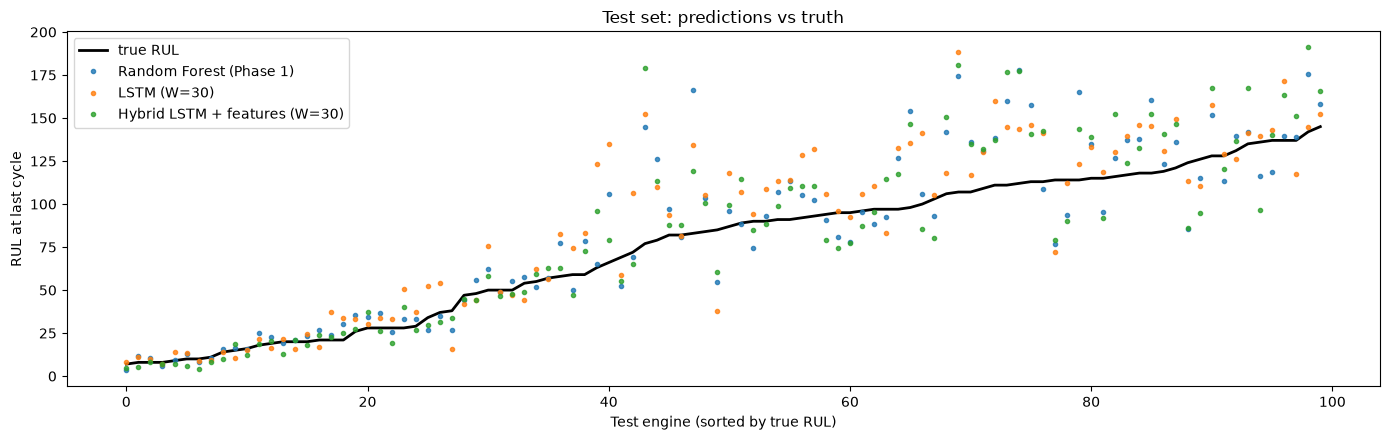

In [16]:
# Test predictions vs truth, engines sorted by true RUL
o = np.argsort(y_test)
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(y_test[o], "k-", lw=2, label="true RUL")
for n in ["Random Forest (Phase 1)", "LSTM (W=30)", "Hybrid LSTM + features (W=30)"]:
    ax.plot(test_preds[n][o], ".", ms=6, alpha=0.8, label=n)
ax.set_xlabel("Test engine (sorted by true RUL)")
ax.set_ylabel("RUL at last cycle")
ax.set_title("Test set: predictions vs truth")
ax.legend()
plt.tight_layout()
save_fig("phase2_test_predictions.png")
plt.show()

## 15. Findings

All statements below are read from the tables printed above (CV = 5-fold `GroupKFold`, mean ± std over folds; test = 100 engines at their last cycle, mean over 3 seeds).

**1. Raw sensor windows alone do not match the engineered features.** The LSTM on 30-cycle raw windows reaches CV RMSE 41.76 ± 1.70 against 35.17 ± 1.52 for the Phase 1 Random Forest re-run on the same folds. The gap (6.6 cycles) is larger than the fold standard deviation, so it is real. The difference is largest near failure: late-stage MAE 12.33 for the LSTM against 5.02 for the Random Forest.

**2. The LSTM overfits the training engines within a few epochs.** Best epochs were 1 to 6 in every fold. In the learning curves, training error keeps falling while inner-validation error is flat or rises after the first epochs. A 30-cycle window does not show how old an engine is or what its healthy readings were, so early in life many windows look alike while their RUL differs by more than 100 cycles; the network can fit training engines but that does not transfer to new ones.

**3. Window length, dropout and architecture matter little.** Window 10 is worse (43.12 ± 0.99) than 30 (41.76 ± 1.70) and 50 (41.61 ± 3.02); 30 and 50 are within noise, so 30 is kept. Removing dropout gives 40.89 ± 3.59, within noise of 41.76. The temporal CNN scores 44.06 ± 3.56, also within the fold spread of the LSTM. None of these changes closes the gap to the engineered features.

**4. Adding the engineered features fixes most of the gap, but the LSTM branch adds nothing measurable.** The hybrid reaches CV RMSE 35.05 ± 2.19 and late MAE 6.00, close to the Random Forest. However, an MLP fed only the 57 features scores 34.20 ± 3.27, so the improvement comes from the features, not from the sequence. On FD001, with this window, the hybrid is justified by the long-term-context argument but not supported by the ablation.

**5. Capping still hurts on the true target.** The hybrid trained on RUL capped at 125 scores CV RMSE 46.02 ± 1.81 on uncapped RUL, worse than uncapped (35.05), because it cannot predict above 125 early in life. It has the lowest late-stage MAE of all models (3.60), which is why many papers use the cap when they care mainly about the end of life.

**6. Test set (used once).** RMSE: MLP 21.59 ± 0.44, Random Forest 23.32, hybrid 25.23 ± 0.15, LSTM 25.33 ± 3.55, CNN 26.27 ± 0.74. The order of the learned-feature models matches CV. The MLP's lower test RMSE than the Random Forest should not be read as a win: their CV difference (34.20 vs 35.17) is within noise, and the test score is one cycle on each of 100 engines. The raw LSTM varies a lot between seeds (± 3.55), consistent with its short, unstable training.

**Answer to the project question.** On FD001 with an uncapped target, engineered degradation features (rolling mean, slope, drift from the engine's own start, and cycle number) carry more usable information than a 30-cycle raw window. The raw LSTM does learn degradation: its late-stage MAE (12.33) is far better than the Phase 1 Elastic Net's (23.35). Its overall CV RMSE (41.76), however, is no better than the Elastic Net's (40.04, from the Phase 1 run), because early-life RUL needs long-term context that a short window cannot provide and the engineered features can.

## 16. Limitations

- **No hyperparameter search.** Layer sizes, learning rate, dropout and weight decay are fixed defaults. Ablations vary one setting at a time, so interactions between settings are not explored.
- **Ablations use the same folds as the model comparison**, so the best ablation's CV score is slightly optimistic. The test set is the unbiased check, used once.
- **Seeds.** CV ablations use one seed (42). Differences smaller than the fold standard deviation should not be read as real.
- **Padding.** Early rows are padded by repeating the first reading. The model may learn that a padded (flat) window means a young engine, which is legitimate (it uses only the past) but means the window length interacts with the start of life.
- **Test variance.** 100 engines, one cycle each.
- **FD001 only**, one operating condition and one fault mode. FD002 to FD004 would test whether the models generalise across regimes.
- **Uncapped target.** Results are not directly comparable to papers that cap RUL at 125 and report test RMSE around 12 to 18.

## 17. Reproducibility

- Seeds fixed for Python, NumPy and PyTorch. On CPU, results are repeatable on the same machine and library versions; GPU runs may differ slightly.
- Same row order and `GroupKFold` as Phase 1, so the folds are identical.
- All preprocessing statistics (sensor normalisation, feature standardisation) are fitted on training engines only, inside each fold.

In [17]:
import sklearn
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| torch", torch.__version__)

numpy 2.5.4 | pandas 3.1.1 | scikit-learn 1.9.1 | torch 2.15.0
